In [ ]:
import pandas as pd

df = pd.read_csv("heart_disease_uci.csv")

print(df.shape)      # (rows, columns)
df.head()            # first 5 rows

(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [ ]:
df.info()                 # column names and types
df.isnull().sum()         # missing values per column
df.describe()             # basic statistics

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


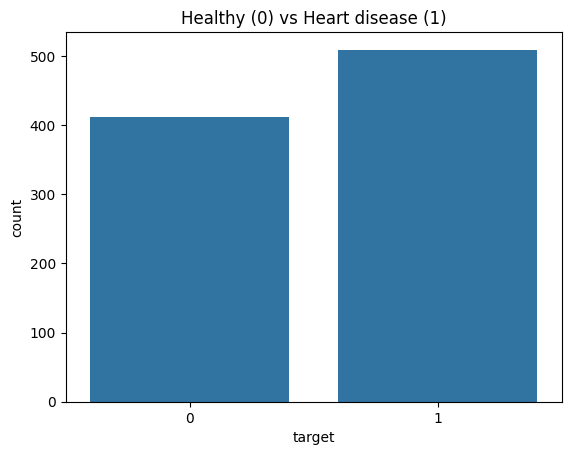

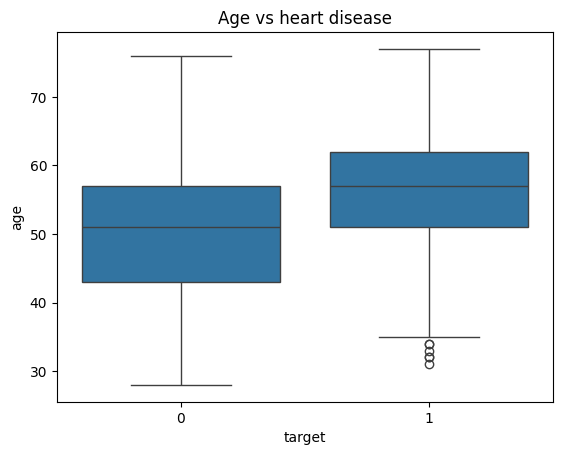

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["target"] = (df["num"] > 0).astype(int)   # 0 = healthy, 1 = heart disease

sns.countplot(x="target", data=df)
plt.title("Healthy (0) vs Heart disease (1)")
plt.show()

sns.boxplot(x="target", y="age", data=df)
plt.title("Age vs heart disease")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = df.drop(columns=["id", "dataset", "num"])

num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

df[cat_cols] = df[cat_cols].astype(str)

X = df[num_cols + cat_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Training patients:", X_train.shape[0])
print("Test patients:", X_test.shape[0])

Training patients: 736
Test patients: 184


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, eval_metric="logloss"),
}

results = []
trained = {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    trained[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

pd.DataFrame(results).round(3)



,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.826,0.824,0.873,0.911
1,Random Forest,0.853,0.857,0.882,0.929
2,XGBoost,0.848,0.836,0.902,0.902


In [ ]:
import joblib
from google.colab import files

best_name = max(results, key=lambda r: r["ROC-AUC"])["Model"]
print("Winner:", best_name)

joblib.dump(trained[best_name], "heart_model.pkl")
files.download("heart_model.pkl")

Winner: Random Forest


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for c in cat_cols:
    print(c, df[c].unique())

import sklearn, xgboost
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)

sex ['Male' 'Female']
cp ['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']
fbs ['True' 'False' 'nan']
restecg ['lv hypertrophy' 'normal' 'st-t abnormality' 'nan']
exang ['False' 'True' 'nan']
slope ['downsloping' 'flat' 'upsloping' 'nan']
thal ['fixed defect' 'normal' 'reversable defect' 'nan']
scikit-learn: 1.6.1
xgboost: 3.4.1
